# 퍼셉트론 & 딥러닝 기초 — 과제

INSIGHT 15기 · 심화 세션 2차

---

**안내**

- 수업 시간 실습에서는 **직접 돌려서 확인**했다면, 과제는 **직접 판단하고 골라 보는** 것이 목적입니다.
- `# 여기를 채우세요` 표시가 있는 칸을 채우거나, `**답:**` 아래에 본인의 생각을 적어주세요.
- 코드의 `None` 부분은 **`None`을 지우고** 적절한 숫자나 문자열로 바꾸세요. 채우기 전에는 해당 셀을 실행하지 마세요.
- 코드 문제는 **채우고 나면 실행이 됩니다.** 실행해서 결과가 맞는지 스스로 확인해 보세요.
- 서술 문제는 **정답 문장을 맞히는 게 아니라**, 왜 그렇게 생각했는지가 중요합니다. 짧아도 좋으니 이유를 적어주세요.

## 0. 환경 설정

제일 먼저 한 번만 실행해 주세요.

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec('tensorflow') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'tensorflow'])

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

try:                                   # 한글 폰트
    import koreanize_matplotlib
except ImportError:                    # 처음 한 번은 설치가 필요합니다
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "koreanize_matplotlib"])
    import koreanize_matplotlib

print("준비 완료")

준비 완료


---
# Part 1. 퍼셉트론과 논리 게이트

강의 `1장`에서 다룬 내용입니다.

## 문제 1. 가중치만 보고 무슨 게이트인지 맞히기

아래 네 개의 퍼셉트론이 있습니다. 각각 어떤 논리 게이트일까요?

**먼저 종이에 직접 계산해 보고**, 그다음 코드를 실행해 확인해 보세요.

In [2]:
def perceptron(x1, x2, w1, w2, b):
    return 1 if x1 * w1 + x2 * w2 + b > 0 else 0

INPUTS = [(0, 0), (0, 1), (1, 0), (1, 1)]

candidates = {
    "A": (1.0,  1.0, -1.5),
    "B": (-1.0, -1.0, 1.5),
    "C": (2.0,  2.0, -1.0),
    "D": (0.5,  0.5, -0.7),
}

for name, (w1, w2, b) in candidates.items():
    out = [perceptron(x1, x2, w1, w2, b) for x1, x2 in INPUTS]
    print(f"{name}: w1={w1:>5}, w2={w2:>5}, b={b:>5}  ->  출력 {out}")

A: w1=  1.0, w2=  1.0, b= -1.5  ->  출력 [0, 0, 0, 1]
B: w1= -1.0, w2= -1.0, b=  1.5  ->  출력 [1, 1, 1, 0]
C: w1=  2.0, w2=  2.0, b= -1.0  ->  출력 [0, 1, 1, 1]
D: w1=  0.5, w2=  0.5, b= -0.7  ->  출력 [0, 0, 0, 1]


**답:**

| 퍼셉트론 | 무슨 게이트인가 | 그렇게 판단한 이유 |
|---|---|---|
| A | AND 게이트 | 두 입력이 모두 1일 때만 1을 출력하기 때문 |
| B | NAND 게이트 | 두 입력이 모두 1일 때만 0을 출력하기 때문 |
| C | OR 게이트 | 두 입력 중 하나만 1이어도 1을 출력하기 때문 |
| D | AND 게이트 | 두 입력이 모두 1일 때만 1을 출력하기 때문 |

> 추가 질문 — **A와 D는 출력이 완전히 같습니다.** 그런데 가중치는 다르죠.
> 같은 게이트를 만드는 가중치 조합이 여러 개인 이유는 무엇일까요?
>
> A와 D는 가중치화 편향의 값이 서로 다르지만, 모든 입력 조합에 대해 동일한 출력을 생산하기 때문에 둘 다 AND 게이트라고 할 수 있다. 퍼셉트론은 입력값과 가중치의 곱에 편향을 더한 결과가 0이상인지를 판단하여 출력을 결정하기 때문에, 가중치와 편향이 다르더라도 최종 결과의 부호가 동일하다면 같은 출력을 얻을 수 있다.

## 문제 2. NOR 게이트를 직접 설계하기

수업에서는 AND, OR, NAND를 다뤘습니다. 이번엔 **NOR**입니다.

NOR은 **둘 다 0일 때만 1**을 출력합니다.

| x1 | x2 | y |
|---|---|---|
| 0 | 0 | **1** |
| 0 | 1 | 0 |
| 1 | 0 | 0 |
| 1 | 1 | 0 |

`w1, w2, b`를 직접 정해서 `4/4`를 만들어 보세요.

In [3]:
NOR_ANSWER = [1, 0, 0, 0]

def NOR(x1, x2):
    # 여기를 채우세요: None을 지우고 숫자를 입력하세요.
    w1, w2 = -1, -1
    b = 0.5
    return 1 if x1 * w1 + x2 * w2 + b > 0 else 0

correct = 0
for (x1, x2), ans in zip(INPUTS, NOR_ANSWER):
    out = NOR(x1, x2)
    correct += (out == ans)
    print(f"({x1}, {x2}) -> {out}   정답 {ans}   {'O' if out == ans else 'X'}")
print(f"=> {correct}/4")

(0, 0) -> 1   정답 1   O
(0, 1) -> 0   정답 0   O
(1, 0) -> 0   정답 0   O
(1, 1) -> 0   정답 0   O
=> 4/4


**답:**

> NOR는 OR와 어떤 관계인가요? 그 관계가 가중치에는 어떻게 나타났는지 설명해 주세요.
>
> NOR 은 OR 게이트의 출력을 반대로 만든 게이트이다. OR은 두 입력 중 하나라도 1이면 1을 출력하는 반면, NOR은 두 입력이 모두 0이어야 1을 출력한다. NOR은 가중치와 편향의 부호를 모두 반대로 바꾸어 계산 결과의 부호를 반전시켜 OR과 반대되는 출력을 만들어낼 수 있다

## 문제 3. XOR을 다층 퍼셉트론으로 해결하기

실습에서 **단층으로는 XOR이 불가능**하다는 걸 68,921개 조합으로 확인했습니다.

강의 `1-3`에서는 **게이트를 조합하면** 된다고 했죠. 직접 조합해 보세요.

먼저 아래 표의 빈칸을 **손으로 채워 보고**, 그다음 코드를 완성하시면 됩니다.

| x1 | x2 | s1 = NAND(x1,x2) | s2 = OR(x1,x2) | y = AND(s1,s2) | XOR 정답 |
|---|---|---|---|---|---|
| 0 | 0 | 1 | 0 | 0 | 0 |
| 0 | 1 | 1 | 1 | 1 | 1 |
| 1 | 0 | 1 | 1 | 1 | 1 |
| 1 | 1 | 0 | 1 | 0 | 0 |

In [4]:
def AND(x1, x2):  return perceptron(x1, x2,  0.5,  0.5, -0.7)
def OR(x1, x2):   return perceptron(x1, x2,  0.6,  0.6, -0.5)
def NAND(x1, x2): return perceptron(x1, x2, -0.5, -0.5,  0.7)

def XOR(x1, x2):
    # 여기를 채우세요: None을 지우고 위 세 게이트를 조합하세요.
    s1 = NAND(x1, x2)
    s2 = OR(x1, x2)
    return AND(s1, s2)

XOR_ANSWER = [0, 1, 1, 0]
print(" x1  x2 | s1  s2 |  y  | 정답")
print("--------|--------|-----|-----")
for (x1, x2), ans in zip(INPUTS, XOR_ANSWER):
    s1, s2, y = NAND(x1, x2), OR(x1, x2), XOR(x1, x2)
    print(f"  {x1}   {x2}  |  {s1}   {s2}  |  {y}  |  {ans}   {'O' if y == ans else 'X'}")

 x1  x2 | s1  s2 |  y  | 정답
--------|--------|-----|-----
  0   0  |  1   0  |  0  |  0   O
  0   1  |  1   1  |  1  |  1   O
  1   0  |  1   1  |  1  |  1   O
  1   1  |  0   1  |  0  |  0   O


**답:**

> 단층으로는 68,921개를 다 넣어도 안 되던 것이, 층을 하나 더 쌓으니 되었습니다.
> **층이 하나 늘어난 것이 무엇을 가능하게 만든 걸까요?** 실습 1의 산점도를 떠올리며 설명해 주세요.
>
> 층을 하나 더 추가하며, 단층 퍼셉트론의 선형성에서 새로운 은닉층이 추가되며 비선형을 띄게 되며, 문제를 해결할 수 있게 되었다.

## 문제 4. 행렬 연산으로 표현하기

방금 만든 XOR은 게이트 함수를 세 번 호출했습니다.
실제 딥러닝은 이걸 **행렬 곱 한 번**으로 처리합니다.

$$\mathbf{a} = \mathbf{W}\mathbf{x} + \mathbf{b}$$

1층은 NAND와 OR **두 뉴런**을 동시에 계산합니다. 각 뉴런이 `W1`의 한 **행**이 됩니다.

In [6]:
def step(x):
    return (x > 0).astype(int)

def XOR_matrix(x1, x2):
    X = np.array([x1, x2])

    # 여기를 채우세요: None을 지우고 문제 3의 가중치·편향을 옮기세요.
    W1 = np.array([[-0.5, -0.5],      # 1행 = NAND 뉴런의 가중치
                   [0.6, 0.6]])     # 2행 = OR 뉴런의 가중치
    b1 = np.array([0.7, -0.5])       # [NAND 편향, OR 편향]

    W2 = np.array([0.5, 0.5])       # 2층 = AND 뉴런
    b2 = -0.7

    Z1 = step(W1 @ X + b1)            # -> [s1, s2]
    Z2 = step(W2 @ Z1 + b2)           # -> y
    return Z1, int(Z2)

for (x1, x2), ans in zip(INPUTS, XOR_ANSWER):
    (s1, s2), y = XOR_matrix(x1, x2)
    print(f"({x1}, {x2}) -> s1={s1}, s2={s2}, y={y}   정답 {ans}   {'O' if y == ans else 'X'}")

(0, 0) -> s1=1, s2=0, y=0   정답 0   O
(0, 1) -> s1=1, s2=1, y=1   정답 1   O
(1, 0) -> s1=1, s2=1, y=1   정답 1   O
(1, 1) -> s1=0, s2=1, y=0   정답 0   O


## 문제 5. 가중치를 사람이 아니라 **기계가** 찾게 하기

여기까지는 전부 **사람이 손으로** 가중치를 정했습니다.

| 문제 | 정해야 할 파라미터 |
|---|---|
| AND 게이트 | 3개 |
| 손글씨 분류 (28×28) | 수천 개 |
| GPT-3 | **1,750억 개** |

사람이 할 수 있는 규모가 아니죠. 그래서 **역전파**로 자동으로 찾습니다.

아래는 XOR을 역전파로 학습시키는 코드입니다.
**기울기를 구하는 두 줄**이 비어 있습니다. 강의 `2-1`의 연쇄법칙을 떠올려 채워보세요.

- 출력층 오차 신호 = (예측 − 정답) × (출력층 활성화 함수의 미분)
- 은닉층 오차 신호 = (출력층 오차 신호를 되돌려 받은 값) × (은닉층 활성화 함수의 미분)

In [13]:
def sigmoid(x):        return 1 / (1 + np.exp(-x))
def sigmoid_deriv(x):  s = sigmoid(x); return s * (1 - s)

X_train = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)
y_train = np.array([[0],  [1],  [1],  [0]],   dtype=float)

np.random.seed(42)
W1 = np.random.randn(2, 4) * 0.5;  b1 = np.zeros((1, 4))
W2 = np.random.randn(4, 1) * 0.5;  b2 = np.zeros((1, 1))

lr, epochs = 0.05, 5000
loss_history = []

for epoch in range(epochs):
    z1 = X_train @ W1 + b1;  a1 = sigmoid(z1)          # 순전파
    z2 = a1 @ W2 + b2;       a2 = sigmoid(z2)

    loss = np.mean((a2 - y_train) ** 2)                # 손실 (MSE)
    loss_history.append(loss)

    # 여기를 채우세요: None을 지우고 역전파 식을 입력하세요.
    d2 = (a2 - y_train) * a2 * (1 - a2)
    d1 = (d2 @ W2.T) * a1 * (1 - a1)

    W2 -= lr * (a1.T @ d2);  b2 -= lr * d2.sum(axis=0, keepdims=True)
    W1 -= lr * (X_train.T @ d1);  b1 -= lr * d1.sum(axis=0, keepdims=True)

print(f"처음 손실 : {loss_history[0]:.6f}")
print(f"최종 손실 : {loss_history[-1]:.6f}\n")
for (x1, x2), pred, ans in zip(X_train.astype(int), a2.ravel(), y_train.ravel()):
    print(f"({x1}, {x2}) -> 예측 {pred:.4f}  (반올림 {round(pred)})   정답 {int(ans)}")

처음 손실 : 0.255675
최종 손실 : 0.249659

(0, 0) -> 예측 0.4938  (반올림 0)   정답 0
(0, 1) -> 예측 0.5031  (반올림 1)   정답 1
(1, 0) -> 예측 0.4996  (반올림 0)   정답 1
(1, 1) -> 예측 0.5075  (반올림 1)   정답 0


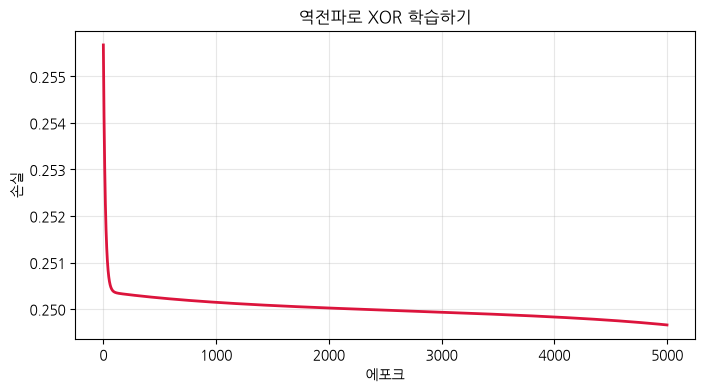

In [14]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history, lw=2, color='crimson')
plt.xlabel('에포크'); plt.ylabel('손실')
plt.title('역전파로 XOR 학습하기'); plt.grid(alpha=0.3); plt.show()

**답:**

> 위 코드에서 `lr`을 **`0.05`로 줄이고** 다시 돌려보세요. 그다음 **`50.0`으로 키워서도** 돌려보세요.
> 각각 손실 그래프의 모양이 어떻게 달라지나요? 그리고 그 이유는 무엇일까요?
>
> lr = 0.05 인 경우에는 손실이 아주 천천히 줄어드는 형태로 기울기가 매우 완만하다. lr = 50.0인 경우에는 손실이 크게 튀거나 높은 값에 멈추는 형태로, 최솟값을 지나쳐 반대편으로 튀는 발산의 형태이다. 이는 학습률과 관련해서 학습률이 너무 크면 학습이 불안정해지고, 너무 작으면 학습속도가 느려지기 때문이다.

---
# Part 2. 딥러닝 모델은 어떻게 학습하는가

강의 `2장`에서 다룬 내용입니다.
여기서부터는 **직접 고르고 판단하는** 문제입니다.

## 문제 6. 손실 함수 고르기

아래 다섯 가지 상황에 알맞은 손실 함수를 `MSE` / `BCE` / `CEE` 중에서 고르고, **왜 그런지** 적어주세요.

강의 `2-2 ②`의 표를 참고하시되, **표를 그대로 베끼지 말고** 각 상황의 어떤 특징 때문에 그 손실 함수인지를 적어주세요.

**답:**

| 상황 | 손실 함수 | 이유 |
|---|---|---|
| 내일 서울의 최고 기온을 예측 | MSE | 기온은 예측값과 실제값의 차이를 측정하는 회귀 문제이기 때문 |
| 이메일이 스팸인지 아닌지 분류 | BCE | 스팸과 정상 메일 두 가지 범주 중 하나 선택하는 이진 분류 문제이기 때문 |
| 손글씨 사진을 0\~9 중 하나로 분류 | CEE | 0 ~ 10 까지의 범주 중 하나를 선택하는 다중 분류 문제이기 때문 |
| 중고차 사진을 보고 가격을 예측 | MSE | 예측 가격과 실제 가격의 차이를 측정해야 하는 회귀 문제이기 때문 |
| 사진 속 동물이 개·고양이·새 중 무엇인지 분류 | CEE | 개·고양이·새 세 가지 범주 중 하나를 선택하는 다중 분류 문제이기 때문 |

## 문제 7. 0.25는 어디서 나온 숫자인가

강의 `2-1 ③`에서 이런 식이 나왔습니다.

$$0.25 \times 0.25 \times 0.25 \times \cdots \approx 0$$

이 `0.25`가 **시그모이드 미분의 최댓값**이라고 했죠. 정말 그런지 직접 확인해 봅시다.

시그모이드 미분의 최댓값 : 0.250000
그때의 x 값              : 0.0000
  은닉층  2개를 지나면 : 0.25^2 = 0.0625000000
  은닉층  5개를 지나면 : 0.25^5 = 0.0009765625
  은닉층 10개를 지나면 : 0.25^10 = 0.0000009537


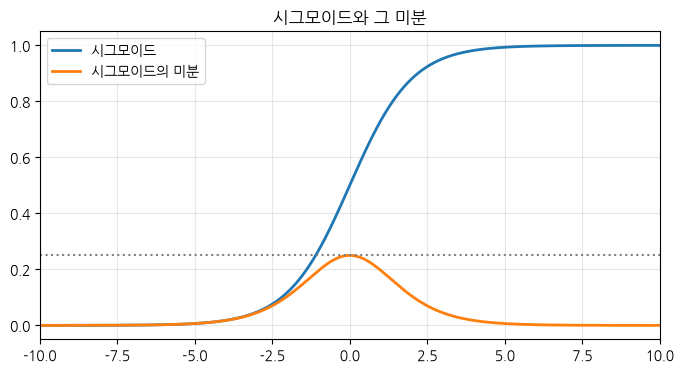

In [16]:
xs = np.linspace(-10, 10, 200001)
# 여기를 채우세요: None을 지우고 시그모이드 미분값을 구하세요.
grad = sigmoid(xs) * (1 - sigmoid(xs))

print(f"시그모이드 미분의 최댓값 : {grad.max():.6f}")
print(f"그때의 x 값              : {xs[grad.argmax()]:.4f}")

for n in [2, 5, 10]:
    print(f"  은닉층 {n:>2}개를 지나면 : 0.25^{n} = {0.25 ** n:.10f}")

plt.figure(figsize=(8, 4))
plt.plot(xs, sigmoid(xs), lw=2, label='시그모이드')
plt.plot(xs, grad, lw=2, label='시그모이드의 미분')
plt.axhline(0.25, ls=':', color='gray'); plt.xlim(-10, 10)
plt.legend(); plt.grid(alpha=0.3); plt.title('시그모이드와 그 미분'); plt.show()

**답:**

> (1) 미분값이 가장 큰 지점이 `x = 0` 입니다. 그래프를 보면 **양 끝으로 갈수록 미분값이 0에 가까워지죠.**
> 입력값이 아주 크거나 아주 작을 때 학습에 어떤 문제가 생길까요?
>
> (2) ReLU는 양수 구간에서 미분값이 **항상 1**입니다.
> 1을 열 번 곱하면 1이고, 0.25를 열 번 곱하면 0.00000095입니다.
> **이 차이가 실제 학습에서 무엇을 바꾸는지** 설명해 주세요.
>
> 1) 입력값이 0에서 멀어질수록 미분값이 0에 가까워진다. 그 결과, 역전파 과정에서 기울기가 거의 전달되지 않아 기울기 소실 문제가 발생하게 된다.
>
> 2) 시그모이드의 경우에는 미분값이 최대 0이므로, 반복해서 곱하면 기울기가 점점 작아진다. 반면 ReLU 함수는 양수 구간에서의 미분값이 1이므로, 기울기가 작아지는 현상을 완화할 수 있다. 그 결과, ReLU가 시그모이드보다 기울기를 효과적으로 전달하여 학습을 빠르고 안정적으로 진행할 때 유리하다. 

## 문제 8. 배치 · 에포크 · 이터레이션

데이터가 **50,000개** 있습니다. 배치 크기를 **128**로 잡고 **10 에포크** 학습시키려고 합니다.

계산해서 채워보세요.

In [22]:
import math

N          = 50000
batch_size = 1
epochs     = 10

# 여기를 채우세요: None을 지우고 계산식을 입력하세요.
iterations_per_epoch = math.ceil(N / batch_size)
total_updates        = iterations_per_epoch * epochs

print(f"1 에포크당 이터레이션 수 : {iterations_per_epoch}")
print(f"전체 가중치 업데이트 횟수 : {total_updates}")

1 에포크당 이터레이션 수 : 50000
전체 가중치 업데이트 횟수 : 500000


**답:**

> 만약 배치 크기를 **50,000(전체)** 으로 바꾸면 업데이트 횟수는 몇 번이 될까요?
> 그리고 배치 크기를 **1**로 바꾸면요?
>
> 강의 `2-4 ④`에서 **미니 배치를 가장 많이 쓴다**고 했습니다. 위 두 극단과 비교해서 그 이유를 설명해 주세요.
>
> 1) 배치 크기를 50,000(전체)로 바꿀 경우 에포크당 이터레이션 수는 1이고, 전체 가중치 업데이트 횟수는 10이다. 배치 크기를 1로 할 경우에는 에포크당 이터레이션 수는 50,000이고, 전체 가중치 업데이트 횟수는 500,000이 된다.
>
> 2) 미니배치는 배치 크기를 적절히 지정하여 해당 개수만큼 매개변수를 조정하기 때문에, 전체 데이터보다 빠르고, 배치 크기 1보다 안정적이어서 가장 많이 사용한다.

## 문제 9. 손실 곡선만 보고 학습률 알아맞히기

**똑같은 모델**을 학습률만 바꿔 세 번 학습시켰습니다. 결과는 아래와 같습니다.

| | 1 에포크 | 10 에포크 | 50 에포크 | 100 에포크 | 최종 정확도 |
|---|---|---|---|---|---|
| **A** | 0.6907 | 0.6900 | 0.6869 | 0.6831 | 0.580 |
| **B** | 4.2903 | 1.9707 | 1.9707 | 1.9707 | 0.538 |
| **C** | 0.6594 | 0.3655 | 0.2541 | 0.2010 | 0.918 |

이 중 하나는 학습률이 **`0.0001`**, 하나는 **`0.1`**, 하나는 **`20.0`** 이었습니다.

> 참고 — 이건 **이진 분류** 문제입니다. 아무것도 학습하지 않고 찍으면 정확도가 약 `0.5`가 나옵니다.

**답:**

| | 학습률 | 그렇게 판단한 이유 |
|---|---|---|
| A | 0.0001| 학습률이 너무 작아 손실이 매우 천천히 감소함. 100에포크 이후에도 정확도가 낮음 |
| B | 20.0 | 학습률이 지나치게 커서 손실이 처음에 급격히 증가 후 계속 높은 손실 유지되어 학습은 실패했음 |
| C | 0.1 | 손실이 지속적으로 감소하고, 최종 정확도가 가장 높아 가장 적절한 학습법임 |

> 추가 질문 — **B는 10 에포크 이후로 손실이 `1.9707`에서 소수점까지 똑같습니다.**
> 줄어들지도, 늘어나지도 않아요. 모델에 무슨 일이 일어난 걸까요?
>
> 가중치가 과도하게 업데이트 되어 학습률이 너무 크기 때문에 기울기가 매우 작아져 기울기 소실 현상이 발생하였기 때문이다 

## 문제 10. 옵티마이저 고르기

실습에서 SGD · 모멘텀 · Adam의 수렴 속도를 비교해 봤습니다.

아래 상황에서는 어떤 옵티마이저를 고르시겠어요?

**답:**

| 상황 | 고른 옵티마이저 | 이유 |
|---|---|---|
| 처음 만들어보는 모델이라 뭘 써야 할지 모르겠다 | Adam | 모멘텀과 RMSProp을 합쳐서 초기 설정이 비교적 쉽고 안정적으로 학습할 수 있기 때문 |
| 손실이 계속 좌우로 튀면서 잘 안 내려간다 | Momentum | 이전 기울기 정보를 활용하여 진동을 줄이고 일관된 방향으로 이동하도록 도와줘야하기 때문 |
| 파라미터마다 기울기 크기 차이가 아주 크다 | Adam | 파라미터별 기울기 크기를 고려하여 학습률을 조절하기 때문에 효율적인 학습이 가능하기 때문 |

> 추가 질문 — **Adam은 모멘텀과 RMSProp을 합친 것**이라고 배웠습니다.
> 그렇다면 **Adam이 있는데도 모멘텀과 RMSProp을 따로 배우는 이유**는 뭘까요?
>
> Adam이 모든 상황에서 항상 최고의 성능을 보이는 것이 아니기 때문에, 적절한 상황에 적절한 옵티마이저를 활용하기 위해서 다른 옵티마이저를 공부해야 한다

## 문제 11. 상황을 읽고 모델을 직접 짜기

> **상황**
> 꽃 사진에서 뽑아낸 **특성 64개**를 입력받아,
> 그 꽃이 **장미 · 튤립 · 해바라기 · 백합 · 국화** 중 무엇인지 맞히는 모델을 만들려고 합니다.
> 데이터는 **12,000장**이고, 한 번에 **64장씩** 묶어서 **30번** 반복 학습시킬 예정입니다.

이 상황에 맞게 코드를 완성하세요. **강의 `2-6`의 코드 세 덩어리 구조 그대로**입니다.

In [24]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

# ① 모델 구조
model = Sequential()
model.add(Input((64,)))                        # None을 지우고 입력 특성 수를 쓰세요.
model.add(Dense(32, activation='relu'))          # 따옴표 안 None만 지우고 은닉층 활성화 함수를 쓰세요.
model.add(Dense(5, activation='softmax'))        # 각 None을 지우고 출력 수와 활성화 함수를 쓰세요.

# ② 학습 방법 설정
model.compile(optimizer='adam',                  # 따옴표 안 None만 지우고 옵티마이저를 쓰세요.
              loss='categorical_crossentropy',                       # 따옴표 안 None만 지우고 손실 함수를 쓰세요.
              metrics=['acc'])

model.summary()

# 가짜 데이터로 30 에포크 학습까지 실행되는지 확인합니다.
X_fake = np.random.randn(12000, 64)
y_fake = tf.keras.utils.to_categorical(np.random.randint(0, 5, 12000), 5)

# ③ 학습 실행
model.fit(X_fake, y_fake, batch_size=64, epochs=30, verbose=1)   # 각 None을 지우고 값을 쓰세요.

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,245 (8.77 KB)

 Trainable params: 2,245 (8.77 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - acc: 0.2039 - loss: 1.7723
Epoch 2/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - acc: 0.2163 - loss: 1.6497
Epoch 3/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - acc: 0.2338 - loss: 1.6206
Epoch 4/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.2403 - loss: 1.6062
Epoch 5/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - acc: 0.2518 - loss: 1.5968
Epoch 6/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.2581 - loss: 1.5899
Epoch 7/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - acc: 0.2631 - loss: 1.5843
Epoch 8/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - acc: 0.2682 - loss: 1.5795
Epoch 9/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - acc: 0.2724 - loss: 1.5751
Epoch 10/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - acc: 0.2777 - loss: 1.5711
Epoch 11/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - acc: 0.2828 - loss: 1.5674
Epoch 12/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.2867 - loss: 1.5640
Epoch 13/30
188/188 ━━━━━

**답:**

> 위에서 고른 `loss`와 출력층 `activation`을, **왜 그것으로 골랐는지** 상황의 어떤 부분을 근거로 삼았는지 적어주세요.
>
> 그리고 실행 결과에 찍힌 **`188/188`** 이라는 숫자는 무엇을 뜻할까요? (문제 8을 떠올려 보세요)
>
> softmax 를 고른 이유는 5가지 꽃 중 하나를 분류하는 다중 분류 문제이기 때문이다. 손실함수로 categorical_crossentropy를 고른 이유는 5개 중 정답에 해당하는 클래스 예측 확률 평가를 해야하기 때문이다. 또한 정답 데이터가 원-핫 인코딩이다.
>
> 188/188은 한 에포크에서 처리해야하는 총 188개의 미니배치를 모두 학습했다는 것이다.

## 문제 12. 잘못된 코드 찾아 고치기

아래 세 코드는 **각각 상황에 맞지 않는 부분이 있습니다.**
무엇이 잘못됐는지 찾고, 어떻게 고쳐야 하는지 적어주세요.

> 이 코드들은 **실행하지 않아도 됩니다.** 눈으로 읽고 판단하는 문제입니다.

In [ ]:
# ---------- (a) 아파트 가격(억 원)을 예측하는 모델 ----------
model_a = Sequential()
model_a.add(Input((15,)))
model_a.add(Dense(32, activation='relu'))
model_a.add(Dense(1, activation='sigmoid'))
model_a.compile(optimizer='adam', loss='binary_crossentropy')


# ---------- (b) 이메일이 스팸인지 아닌지 판별하는 모델 ----------
model_b = Sequential()
model_b.add(Input((100,)))
model_b.add(Dense(64, activation='relu'))
model_b.add(Dense(1, activation='sigmoid'))
model_b.compile(optimizer='adam', loss='categorical_crossentropy')


# ---------- (c) 손글씨 숫자(0~9)를 분류하는 모델 ----------
model_c = Sequential()
model_c.add(Input((784,)))
model_c.add(Dense(128, activation='softmax'))
model_c.add(Dense(64,  activation='softmax'))
model_c.add(Dense(10,  activation='softmax'))
model_c.compile(optimizer='adam', loss='categorical_crossentropy')

print("코드 셀입니다. 실행하지 않고 읽어보세요.")

**답:**

| | 무엇이 잘못됐나 | 어떻게 고쳐야 하나 | 왜 |
|---|---|---|---|
| (a) | binary_crossentropy | mse | binary_crossentropy는 이진 분류에 사용된다. 아파트 가격 예측은 연속적인 숫자를 예측하는 문제이므로 mse 가 적절하다 |
| (b) | categorical_crossentropy | binary_crossentropy | 스팸 여부를 0 과 1 두 개로 분류하는 이진 분류 문제이기 때문에 binary_crossentropy가 적절하다 |
| (c) | 은닉층 softmax | relu | 다중 분류 문제의 경우에는 은닉층에서 relu를 활용하고 최종 출력층에서는 softmax를 사용한다 |

> 추가 질문 — 세 코드 중 **(c)는 그래도 학습이 되긴 합니다.** 다만 성능이 나쁘죠.
> 나머지 둘과 비교했을 때 (c)의 문제는 성격이 어떻게 다른가요?
>
> c의 경우에는 은닉층도 sigmoid 함수를 활용하는 것이 잘못 된 구조는 아니기 때문에 학습 자체는 가능하다. 그러나 다양한 특징을 학습하는 데 불리할 수 있어 성능이 나쁘기 때문에 relu를 활용하는 게 더욱 적절하다. a, b의 경우는 설정 오류 인 반면, c는 모델 구조에서의 문제라고 할 수 있다

---
## 마지막으로

> 오늘 강의의 첫 화면에 이런 질문이 있었습니다.
>
> **"모델을 짤 때 내가 정해야 하는 게 뭘까요? 그리고 뭘 기준으로 정하나요?"**
>
> 과제를 다 푼 지금, 이 질문에 **본인의 문장으로** 답해 주세요.
>
> 모델을 짤 때 가장 먼저 정해야 할것은 어떤 문제를 해결할 것인가 이다. 그 후, 데이터는 얼마나있고 어떤 특징이 있는지를 확인한다. 이후 이에 맞게 입력층, 은닉층, 출력층을 정한다. 이 떄 활성화 함수와 손실 함수를 어떤 걸 사용할지도 정해야 한다. 또한 학습률이나 배치 크기, 에포크 수도 정해야하는데, 이는 직접 학습을 시켜보며 손실이나 정확도가 어떻게 변하는지를 확인하면서 조절해 나아가야 한다고 생각한다.

---

### 수고하셨습니다